<a href="https://colab.research.google.com/github/predictive-clinical-neuroscience/PCNtoolkit-demo-transfer/blob/main/notebooks/transfer_icbm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer a pretrained normative model to your own site

*PCNtoolkit hands-on · Donders (f)MRI Toolkit 2026*

You collected scans at one site: here, the **ICBM** site of the open FCON1000 dataset (85 healthy adults, ages 19–85). You want a Z-score for every person: how far is their **left precentral gyrus thickness** from what is normal for their age and sex?

You have two options:

1. **Fit your own normative model** on your healthy controls.
2. **Transfer** a model that the PCN lab already trained on **67,000 people from 89 sites**.

We do both with the same 20 healthy controls, and score the remaining 65 people neither model has seen.

[Open in Colab](https://colab.research.google.com/github/predictive-clinical-neuroscience/PCNtoolkit-demo-transfer/blob/main/notebooks/transfer_icbm.ipynb) · [PCNtoolkit docs](https://pcntoolkit.readthedocs.io/en/latest/)

## 1. Install PCNtoolkit
On Colab this takes about a minute. If Colab asks you to restart the session after the install, do so and continue with the next cell.

In [1]:
%pip install -q pcntoolkit==1.4.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
google-colab 1.0.0 requires ipython==7.34.0, but you have ipython 9.18.1 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.10.0 which is incompatible.
jupyter-kernel-gateway 2.5.2 requires jupyter_client<8.0,>=5.2.0, but you have jupyter-client 8.10.0 which is incompatible.


## 2. Imports

In [2]:
import os
import warnings
import zipfile

import numpy as np
import pandas as pd
import requests

import pcntoolkit.util.output
from pcntoolkit import (
    BLR,
    BsplineBasisFunction,
    NormativeModel,
    NormData,
    load_fcon1000,
    plot_centiles_advanced,
)

warnings.simplefilter("ignore")
pcntoolkit.util.output.Output.set_show_messages(False)

## 3. Download the pretrained 67K model

The PCN lab shares its pretrained models on [SURFdrive](https://surfdrive.surf.nl/s/Mb6mZyFmJeCaPcZ?dir=/zip). We use the cortical thickness model: Bayesian linear regression with a warp (`BLRw`), Destrieux atlas (`DES`), 67,000 people from 89 sites. None of these 89 sites is part of FCON1000, so ICBM is new to the model.

In [3]:
MODEL_NAME = "BLRw_ct_DES_lifespan_67K_89sites"
BASE_URL = "https://surfdrive.surf.nl/public.php/webdav/zip/"
SHARE_TOKEN = "Mb6mZyFmJeCaPcZ"

os.makedirs("models", exist_ok=True)
zip_path = f"models/{MODEL_NAME}.zip"
model_dir = f"models/{MODEL_NAME}"

if not os.path.exists(zip_path):
    r = requests.get(BASE_URL + MODEL_NAME + ".zip", auth=(SHARE_TOKEN, ""), stream=True)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 20):
            f.write(chunk)
if not os.path.exists(model_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(model_dir)

big_model = NormativeModel.load(model_dir)
print("covariates:", big_model.covariates)
print("batch effects:", list(big_model.unique_batch_effects))
print("brain measures:", len(big_model.response_vars))

covariates: ['age']
batch effects: ['site', 'sex']
brain measures: 150


## 4. Your data: the ICBM site

One row per person: age (covariate), site and sex (batch effects), and the brain measure, with the same column name the pretrained model uses.

In [4]:
REGION = "lh_G_precentral_thickness"

fcon = load_fcon1000().to_dataframe()
fcon.columns = [c[1] if isinstance(c, tuple) else c for c in fcon.columns]

icbm = fcon[fcon["site"] == "ICBM"][["site", "sex", "age", REGION]].dropna()
icbm["sub_id"] = icbm.index.astype(str)  # FCON1000 subject id
icbm = icbm.reset_index(drop=True)
print(f"{len(icbm)} people, ages {icbm.age.min():.0f}-{icbm.age.max():.0f}")
print(icbm.sex.value_counts().to_string())
icbm.head()

85 people, ages 19-85
sex
F    45
M    40


,site,sex,age,lh_G_precentral_thickness,sub_id
0,ICBM,M,25.0,2.474,580
1,ICBM,F,48.0,2.682,581
2,ICBM,M,26.0,1.978,582
3,ICBM,M,70.0,2.422,583
4,ICBM,F,19.0,2.456,584


## 5. Choose your healthy controls

We take `N_CONTROLS` healthy controls to fit or transfer the model, keeping the women/men ratio. Everyone else is the **test set**: people the models have not seen, on which we check the Z-scores.

`SEED` picks which people end up as controls. With `N_CONTROLS = 20` and `SEED = 0` you get the same split as on the slides and the default view of the web app.

In [5]:
N_CONTROLS = 20
SEED = 0

def split_controls(df, n, seed):
    rng = np.random.default_rng(seed)
    groups = {sex: idx.values for sex, idx in df.groupby("sex").groups.items()}
    alloc = {sex: max(2, int(round(n * len(idx) / len(df)))) for sex, idx in groups.items()}
    controls = np.sort(np.concatenate([rng.choice(idx, alloc[sex], replace=False) for sex, idx in groups.items()]))
    return df.loc[controls], df.drop(index=controls)

controls_df, test_df = split_controls(icbm, N_CONTROLS, SEED)

def to_normdata(df, name):
    return NormData.from_dataframe(
        name, df, covariates=["age"], batch_effects=["site", "sex"],
        response_vars=[REGION], subject_ids="sub_id",
    )

controls = to_normdata(controls_df, "controls")
test = to_normdata(test_df, "test")
print(f"controls: {len(controls_df)} ({controls_df.sex.value_counts().to_dict()})   test: {len(test_df)}")

controls: 20 ({'F': 11, 'M': 9})   test: 65


## 6. Option 1: fit your own model

A warped Bayesian linear regression with B-spline age curves, as in the PCNtoolkit tutorials. `fixed_effect=True` lets the model learn a separate offset for each batch effect, here women and men, just like the 67K model does.

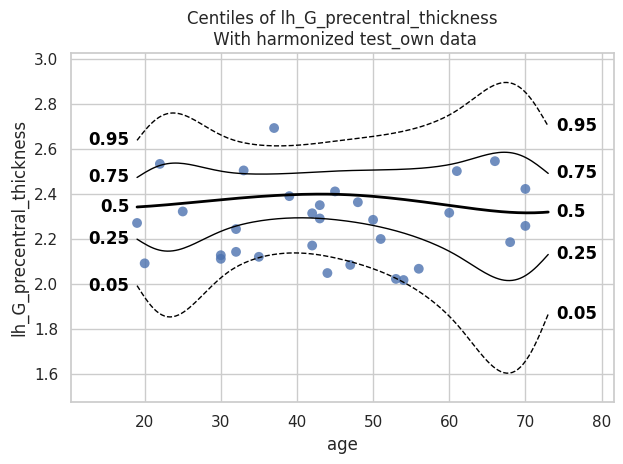

In [6]:
own_template = BLR(
    name="own",
    heteroskedastic=True,
    fixed_effect=True,
    warp_name="WarpSinhArcsinh",
    basis_function_mean=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
    basis_function_var=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
)
own_model = NormativeModel(
    template_regression_model=own_template,
    inscaler="standardize", outscaler="standardize",
    savemodel=False, saveresults=False, saveplots=False, evaluate_model=True,
    save_dir="results/own",
)
own_test = own_model.fit_predict(controls, to_normdata(test_df, "test_own"))
# The plot shows the curves and test people of one reference group (here women);
# everyone, men included, still gets a Z-score.
plot_centiles_advanced(own_model, scatter_data=own_test, show_legend=False);

## 7. Option 2: transfer the 67K model

Transfer keeps the age curve the big model learned from 67,000 people and only learns, from your controls, how much your site is shifted and how wide it scatters, separately for women and men.

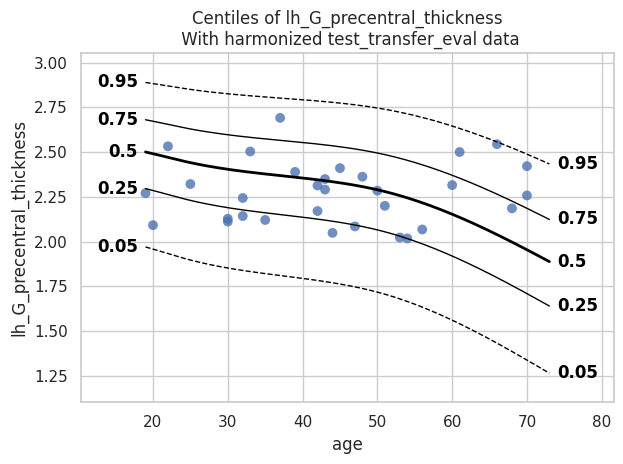

In [7]:
transferred_model = big_model.transfer_predict(
    controls, to_normdata(test_df, "test_transfer"), save_dir="results/transfer"
)
tr_test = to_normdata(test_df, "test_transfer_eval")
transferred_model.predict(tr_test)
plot_centiles_advanced(transferred_model, scatter_data=tr_test, show_legend=False);

## 8. Compare on the people neither model has seen

Two checks of the Z-score **distribution** of healthy people:

- **outside |Z| > 2**: should be about 5%.
- **MACE** (mean absolute centile error): for the 5th, 25th, 50th, 75th and 95th centile, how far the share of people below that centile is from what it should be; computed per sex, then averaged. 0 is perfect.

In [8]:
def scores(data):
    z = data.Z.sel(response_vars=REGION).values
    return {
        "outside |Z|>2 (%)": round(float(np.mean(np.abs(z) > 2) * 100), 1),
        "MACE": round(float(data.statistics.sel(response_vars=REGION, statistic="MACE")), 3),
    }

pd.DataFrame({"fit on my site only": scores(own_test), "67K transfer": scores(tr_test)})

,fit on my site only,67K transfer
outside |Z|>2 (%),15.400,12.300
MACE,0.139,0.103


## 9. Your turn

- Set `N_CONTROLS` to 5, 10, 30 or 60 in section 5 and run everything from there again. When does transfer matter most?
- Change `SEED` to get a different set of controls. Which model changes more?
- Change `REGION` to another thickness column, e.g. `rh_G_precentral_thickness`.

The [web app](https://predictive-clinical-neuroscience.github.io/PCNtoolkit-demo-transfer/) shows all of these, precomputed.

**Your own data:** replace `icbm` with your table (same column names as the model, sex coded `F`/`M`), keep healthy controls for transfer, and score everyone else, including patients. No Python? [PCNportal](https://pcnportal.dccn.nl/) does the same transfer in the browser.

Questions: [NeuroStars, tag pcntoolkit](https://neurostars.org/tag/pcntoolkit) · [GitHub issues](https://github.com/predictive-clinical-neuroscience/PCNtoolkit/issues)